# Do feature combinations beat the `mag_std` threshold? (moving vs still, wrist, ESP32-C3-sized models)

## The short answer

**Under the rule you set in advance: keep the threshold.** The best combination clears the bar on the held-out Capture-24 people, but it does not hold on GOTOV, so it fails the second condition.

| | 2.56 s `mag_std` threshold | Locked candidate | Gain | Needed |
|---|---|---|---|---|
| **11 held-out people** (balanced accuracy) | 0.740 | 0.800 | **+6.0 points** (95% CI +4.2 to +7.8) | 3 |
| **GOTOV** | 0.925 | 0.915 | **-1.0 points** (95% CI -2.0 to 0.0) | 3 |
| ESP32-C3 cost (estimate) | | 1.8% CPU, 10.7 kB RAM, 116 kB flash | passes my limits | |

The candidate was chosen by cross-validation on the 140 training people, and saved to disk before any held-out person or GOTOV window was loaded: a **forest of 20 depth-8 trees on 10 s windows with all four feature groups (16 features)**. The same set was chosen for the sleep target.

## What I found

- **There is a real gain on Capture-24.** All 11 held-out people improve, by about 3 to 11 points each. Block-level false alerts drop too: at 30 minutes the pooled false-alert rate goes from 18.8% to 8.0% (a new-person threshold gives 21.0% to 9.5%).
- **More than a third of that is just the longer window.** The 10 s `mag_std` threshold alone scores 0.763, so the features add 3.7 points on top of the 2.3 that come from the window length.
- **Group 2 (magnitude shape) helps in both datasets.** It adds 1.3 points on the held-out people and 1.5 on GOTOV at 10 s.
- **Frequency and wrist angle help on Capture-24 and hurt on GOTOV.** At 10 s, frequency adds 1.6 then costs 0.7 on GOTOV, and wrist angle adds 0.8 then costs 1.8 on GOTOV. The wrist angle reads very differently in the two datasets (section 10), so it's a poor bet for a third sensor.
- **No set reaches +3 on GOTOV, whatever the window length.** The best GOTOV forest scores 0.941 against a threshold at 0.928. GOTOV has little room: its threshold already scores 0.93.
- **Logistic regression is not better.** The forest beat it in every cross-validation row, by 0.1 to 7.5 points.

## Things that look off, and affect how far to trust this

1. **GOTOV counts standing as "moving", but scripted standing is as still as sitting** (median `mag_std` 0.009 g against 0.006 to 0.008 g for sitting). With standing removed, every method scores higher and the threshold is *ahead* of the candidate (0.958 against 0.944). So the GOTOV result is partly a label problem, not only a model one. I kept the Walmsley rule that standing is moving, as planned.
2. **The wrist angle doesn't mean the same thing in the two datasets.** For sitting, GOTOV's median roll is 8 degrees but its middle half spans -159 to +136, nearly the whole circle. Capture-24's middle half spans -37 to +59. The sensor axes are probably mounted differently, and your MPU-6050 will differ again.
3. **The 11 held-out people are not fresh.** Parts 2 and 3 of `capture24_windows.ipynb` already scored them, and 9 of 11 are aged 53+ (against 25 of 140 in training). It is a final check, not a first look.
4. **The sleep target can't be confirmed on GOTOV.** GOTOV has no sleep, so about 3 minutes of awake lying stands in, and even the best forests find only a third of those windows. Held-out gain is +5.3 points (CI +2.7 to +7.6), GOTOV is +1.3 (CI -4.0 to +6.9). That's "not confirmed", not "no effect".
5. **GOTOV is too small for the 30-minute check.** It has 1 still block at 30 minutes (and 0 for the candidate), so I report no number there.
6. **`mag_std` has a low importance (0.02) in the forest.** That is because the magnitude-shape features (0.64) and `total_power` (almost `mag_std` squared) carry much the same information. Importance splits credit among correlated features, so it doesn't mean `mag_std` is useless.

## In plain language

Telling "moving" from "still" using only how much the wrist's strength varies (`mag_std`) is a good start. I tested whether a small forest looking at 10 seconds of movement, with extra clues such as the shape of the movement, its rhythm and the wrist's tilt, would do clearly better, and it does on Capture-24: about 6 points, for every one of the 11 people I held back, and noticeably fewer false alerts over 10 to 30 minutes. It would also fit on the chip (an estimate: under 2% of the processor and about 116 kB of flash).

But your rule also asked the gain to hold on the older, scripted GOTOV group, and it doesn't: the forest scores slightly lower (0.915 against 0.925). Two reasons stand out: GOTOV's "standing" is nearly as still as sitting but is labelled moving, and the wrist-tilt features read very differently in GOTOV. So the honest verdict is **keep the threshold for now**, with a clear lead on what to try next: a version without wrist angle, checked on your own MPU-6050 recordings.

## 1. Setup

**Kernel:** use `anaconda4` (it has pyarrow). The reusable code is in `feature_sets.py`. The long steps (building the windows, cross-validation, the final fits) are cached under `data/processed/`, so this notebook re-runs in a few minutes. The cached steps were run once by `feature_sets.build_capture24_person`, `build_gotov`, `run_cv` and `run_final`.

**The rule, fixed before any held-out score was seen.** Adopt a feature set only if it beats the `mag_std` threshold by at least 3 points of balanced accuracy on the 11 held-out people, the gain holds on GOTOV (also at least 3 points), and it is cheap enough for an ESP32-C3. Otherwise keep the threshold.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score, roc_auc_score

import feature_sets as F

pd.set_option('display.max_columns', 40, 'display.max_rows', 100, 'display.width', 200, 'display.float_format', '{:,.3f}'.format)

GAIN_NEEDED = 0.03          # points of balanced accuracy, on the 11 held-out people AND on GOTOV
COLOURS = {'2.56s': '#2a78d6', '5s': '#eb6834', '10s': '#1baf7a'}
INK, INK_2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE, 'figure.dpi': 110,
                     'font.family': 'sans-serif', 'font.sans-serif': ['Segoe UI', 'DejaVu Sans'], 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK_2,
                     'xtick.color': INK_2, 'ytick.color': INK_2, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.7,
                     'axes.axisbelow': True, 'axes.titlesize': 11, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left'})

lock = json.loads(F.LOCK_FILE.read_text())
print('self-test:', F.self_test())
print('locked candidates:', {k: v for k, v in lock.items() if k != 'locked_at'})
assert F.LOCK_FILE.stat().st_mtime < F.FIRST_LOAD_FILE.stat().st_mtime, 'the candidates must be locked before held-out data was loaded'
print('candidates were locked before any held-out data was loaded: yes')

self-test: all checks passed
locked candidates: {'primary': '10s: 1+2+3+4', 'secondary': '10s: 1+2+3+4'}
candidates were locked before any held-out data was loaded: yes


## 2. The data

In [2]:
train_ids, test_ids = F.training_people(), F.test_people()
assert not set(train_ids) & set(test_ids) and len(train_ids) == 140 and len(test_ids) == 11

# window counts per length, for training people (labels only), held-out people and GOTOV
rows = {}
for name in F.LENGTHS:
    tr = F.load_training(name, columns=['label', 'participant_id'])
    ho = F.load_held_out(name, columns=['label', 'participant_id'])
    go = F.load_gotov(name, columns=['label', 'participant_id'])
    keep_tr, y_tr = F.target_y(tr['label'], 'primary')
    keep_ho, y_ho = F.target_y(ho['label'], 'primary')
    y_go = F.gotov_y(go['label'], 'primary')
    rows[name] = {'training windows (no sleep)': keep_tr.sum(), 'training % moving': 100 * y_tr.mean(),
                  'held-out windows (no sleep)': keep_ho.sum(), 'held-out % moving': 100 * y_ho.mean(),
                  'GOTOV windows': len(go), 'GOTOV % moving': 100 * y_go.mean(),
                  'training windows incl. sleep': len(tr)}
display(pd.DataFrame(rows).T)
tr = F.load_training('2.56s', columns=['label', 'participant_id'])
print('training label shares (%), all windows incl. sleep:')
print((100 * tr['label'].value_counts(normalize=True)).round(1).to_string())

,training windows (no sleep),training % moving,held-out windows (no sleep),held-out % moving,GOTOV windows,GOTOV % moving,training windows incl. sleep
2.56s,"2,094,410.000",36.984,"171,091.000",38.179,"33,809.000",64.299,"3,330,614.000"
5s,"1,070,674.000",36.953,"87,462.000",38.141,"17,399.000",64.326,"1,703,669.000"
10s,"532,202.000",36.830,"43,485.000",37.995,"8,669.000",64.206,"848,698.000"


training label shares (%), all windows incl. sleep:
label
sedentary           39.600
sleep               37.100
light               18.500
moderate-vigorous    4.700


In [3]:
# reproduction: the new windowing must match the 42 people processed earlier by capture24_windows.ipynb
bad = []
old_files = sorted(F.OLD_C24_DIR.glob('P*.parquet'))
for f in old_files:
    old, new = pd.read_parquet(f), pd.read_parquet(F.person_path(f.stem, '2.56s'))
    if not (len(old) == len(new) and np.abs(old.mag_std - new.mag_std).max() < 1e-5
            and (old.label == new.label).all() and (old.window_start == new.window_start).all()):
        bad.append(f.stem)
print(f'old Capture-24 parquets compared: {len(old_files)}, mismatches: {bad or "none"}')

eda_gotov = pd.read_parquet(F.GOTOV_CACHE / 'gotov_windows.parquet')
new_gotov = pd.read_parquet(F.gotov_path('2.56s'))
print('GOTOV vs the EDA cache: same rows', len(eda_gotov) == len(new_gotov),
      '| largest mag_std difference', float(np.abs(eda_gotov['mag_std'].to_numpy() - new_gotov['mag_std'].to_numpy()).max()),
      '| same labels', bool((eda_gotov['label'].to_numpy() == new_gotov['label'].to_numpy()).all()))

# the old notebook's rule (tune for plain accuracy) on the old 31/11 split should give 0.0955 g and 0.736
w = pd.concat([pd.read_parquet(f, columns=['mag_std', 'label', 'participant_id']) for f in old_files], ignore_index=True)
w = w[w['label'] != 'sleep']
y = (w['label'] != 'sedentary').astype(int).to_numpy()
is_test = w['participant_id'].isin(test_ids).to_numpy()
cut = F.tune_threshold(w['mag_std'].to_numpy()[~is_test], y[~is_test], 'accuracy')
print(f"old rule on the old split: cut-off {cut:.4f} g, balanced accuracy {balanced_accuracy_score(y[is_test], w['mag_std'].to_numpy()[is_test] > cut):.3f}  (earlier notebook: 0.0955 and 0.736)")

old Capture-24 parquets compared: 42, mismatches: none
GOTOV vs the EDA cache: same rows True | largest mag_std difference 0.0 | same labels True


old rule on the old split: cut-off 0.0955 g, balanced accuracy 0.736  (earlier notebook: 0.0955 and 0.736)


## 3. The feature sets and what they cost on an ESP32-C3

In [4]:
info = F.load_model_info('primary')
rows = []
for set_name, spec in F.FEATURE_SETS.items():
    cost = F.estimate_cost(set_name, info['forests'][set_name]['nodes'])
    rows.append({'feature set': set_name, 'features': len(spec['features']), 'forest nodes': info['forests'][set_name]['nodes'],
                 'CPU %': cost['cpu_pct'], 'RAM kB': cost['ram_kb'], 'flash kB': cost['flash_kb'], 'within limits': cost['passes']})
cost_table = pd.DataFrame(rows).set_index('feature set')
print('ESTIMATE from operation counts (software floating point, 160 MHz, 50% overlap), not a measurement.')
print('limits:', F.LIMITS)
display(cost_table)

ESTIMATE from operation counts (software floating point, 160 MHz, 50% overlap), not a measurement.
limits: {'cpu_pct': 5.0, 'ram_kb': 32.0, 'flash_kb': 256.0}


,features,forest nodes,CPU %,RAM kB,flash kB,within limits
feature set,,,,,,
2.56s: 1,1,9284,0.130,1.250,108.797,True
2.56s: 1+2,8,10140,0.152,1.750,118.828,True
2.56s: 1+2+3,12,10136,0.635,2.750,118.781,True
2.56s: 1+2+3+4,16,10178,1.705,2.750,119.273,True
5s: 1,1,8990,0.127,2.441,105.352,True
5s: 1+2,8,10054,0.152,3.418,117.820,True
5s: 1+2+3,12,10024,0.681,5.371,117.469,True
5s: 1+2+3+4,16,9996,1.750,5.371,117.141,True
10s: 1,1,8484,0.126,4.883,99.422,True


**How to read this:** the cost is an estimate from operation counts, not a measurement. It assumes about 150 cycles for each software-float add or multiply, 800 for a square root and 5,000 for an arctangent, which are rough figures for a chip with no FPU. The real numbers need to be measured on the board. What matters is the order of magnitude: if the CPU share is far below the limit, compute isn't what decides this, and flash, RAM and battery come first.

## 4. Cross-validation on the 140 training people

In [5]:
summary = {t: F.cv_summary(t) for t in ['primary', 'secondary']}
cv_tables = {}
for t, s in summary.items():
    table = s.pivot(index='feature_set', columns='model', values='balanced_accuracy')
    table['forest fold SD'] = s[s['model'] == 'forest'].set_index('feature_set')['fold_sd']
    table['forest AUC'] = s[s['model'] == 'forest'].set_index('feature_set')['auc']
    table['features'] = s.groupby('feature_set')['n_features'].first()
    cv_tables[t] = table.sort_values('forest', ascending=False)
print('MOVING vs STILL: balanced accuracy, 5-fold GroupKFold by person (mean over folds)')
display(cv_tables['primary'])
print('locked candidate:', lock['primary'])

MOVING vs STILL: balanced accuracy, 5-fold GroupKFold by person (mean over folds)


model,forest,logistic,threshold,forest fold SD,forest AUC,features
feature_set,,,,,,
everything (multi-scale),0.823,0.809,NaN,0.006,0.899,48
10s: 1+2+3+4,0.822,0.806,NaN,0.006,0.899,16
5s: 1+2+3+4,0.810,0.791,NaN,0.006,0.889,16
10s: 1+2+3,0.809,0.802,NaN,0.007,0.887,12
10s: 1+2,0.801,0.795,NaN,0.007,0.876,8
2.56s: 1+2+3+4,0.800,0.779,NaN,0.006,0.879,16
5s: 1+2+3,0.795,0.787,NaN,0.007,0.875,12
5s: 1+2,0.785,0.780,NaN,0.007,0.863,8
2.56s: 1+2+3,0.784,0.775,NaN,0.008,0.864,12


locked candidate: 10s: 1+2+3+4


**How to read this:** every number is a mean over 5 folds, each fold holding out whole people, and the fold-to-fold spread is under 1 point, so differences of a point or two are real here. Three things stand out. A longer window helps even with `mag_std` alone (0.757, 0.768, 0.783 at 2.56, 5 and 10 s). Each added group helps a little more (10 s: 0.783, 0.801, 0.809, 0.822). The forest beats logistic regression in every row. The "literal" diagnostic row (absolute min and percentiles) scores 0.775 against 0.773 for the level-free version, so on Capture-24 the calibration offset isn't driving the gain. The multi-scale "everything" set (0.823) is within 0.5 points of the 16-feature 10 s set, so the rule picked the smaller one.

## 5. Final scores: the 11 held-out people and GOTOV, separately

In [6]:
def score_sets(target):
    out = {}
    for ds in ['held_out', 'gotov']:
        rows = {}
        for name in F.LENGTHS:
            p = F.load_predictions(target, name)
            p = p[p['dataset'] == ds]
            rows[f'{name}: threshold'] = {'balanced accuracy': balanced_accuracy_score(p['y'], p['threshold_pred']), 'AUC': roc_auc_score(p['y'], p['mag_std']), 'windows': len(p)}
            for c in [c for c in p.columns if c.startswith('forest::')]:
                set_name = c.split('::')[1]
                rows[set_name] = {'balanced accuracy': balanced_accuracy_score(p['y'], p[c] >= 0.5), 'AUC': roc_auc_score(p['y'], p[c]), 'windows': len(p)}
        out[ds] = pd.DataFrame(rows).T
    return out

final = {t: score_sets(t) for t in ['primary', 'secondary']}
order = list(F.FEATURE_SETS)
both = pd.concat({'11 held-out people': final['primary']['held_out'].drop(columns='windows'),
                  'GOTOV': final['primary']['gotov'].drop(columns='windows')}, axis=1)
extra = [f'{n}: threshold' for n in F.LENGTHS]
print('MOVING vs STILL, every window of that length (so rows with different lengths are on different windows)')
display(both.loc[extra + order])

MOVING vs STILL, every window of that length (so rows with different lengths are on different windows)


11 held-out people                   GOTOV      
                                 balanced accuracy   AUC balanced accuracy   AUC
2.56s: threshold                             0.741 0.824             0.928 0.970
5s: threshold                                0.750 0.830             0.923 0.971
10s: threshold                               0.763 0.839             0.924 0.974
2.56s: 1                                     0.741 0.824             0.928 0.970
2.56s: 1+2                                   0.757 0.843             0.938 0.975
2.56s: 1+2+3                                 0.772 0.858             0.924 0.975
2.56s: 1+2+3+4                               0.782 0.868             0.910 0.968
5s: 1                                        0.750 0.830             0.923 0.971
5s: 1+2                                      0.766 0.852             0.941 0.978
5s: 1+2+3                                    0.781 0.867             0.931 0.979
5s: 1+2+3+4                                  0.789 0.876             0.917 0.971
10s: 1                                       0.763 0.838             0.925 0.974
10s: 1+2                                     0.776 0.862             0.940 0.980
10s: 1+2+3                                   0.792 0.877             0.933 0.983
10s: 1+2+3+4                                 0.800 0.886             0.915 0.969
2.56s: 1+3                                   0.761 0.847             0.908 0.970
2.56s: 1+4                                   0.766 0.851             0.916 0.970
2.56s: 1+2 literal (diagnostic)              0.751 0.836             0.920 0.959
everything (multi-scale)                     0.798 0.885             0.917 0.972

**How to read this:** rows with different window lengths are scored on different windows (longer windows drop more mixed-label stretches), so compare lengths with care. The decision rule below fixes that. On the held-out people every step up the ladder helps. On GOTOV the picture is different: group 2 helps, but frequency and wrist angle make it worse, and the level-free group 2 beats the literal version (0.938 against 0.920 at 2.56 s), which fits GOTOV's calibration offset of about 14 mg.

### The decision rule

The baseline for the rule is the **2.56 s `mag_std` threshold**, scored on the same stretches the candidate sees. Longer windows are dropped more often when a label changes mid-window, so they cover cleaner data, and scoring the threshold on all 2.56 s windows would not be a like-for-like comparison. Each 2.56 s window is therefore kept only if it lies fully inside a 10 s window that survived.

In [7]:
def rule_table(target):
    cand = lock[target]
    length = F.FEATURE_SETS[cand]['length']
    short, long = F.load_predictions(target, '2.56s'), F.load_predictions(target, length)
    mask = F.inside_longer(short, long, F.SECONDS[length])
    model_info = F.load_model_info(target)
    cost = F.estimate_cost(cand, model_info['forests'][cand]['nodes'])
    rows, details = {}, {}
    for ds, label in [('held_out', '11 held-out people'), ('gotov', 'GOTOV')]:
        s_all = short[short['dataset'] == ds]
        sel = (short['dataset'] == ds).to_numpy()
        s = short[sel & mask]
        l = long[long['dataset'] == ds]
        base = balanced_accuracy_score(s['y'], s['threshold_pred'])
        same_length = balanced_accuracy_score(l['y'], l['threshold_pred'])
        cand_score = balanced_accuracy_score(l['y'], l[f'forest::{cand}'] >= 0.5)
        lo, hi = F.bootstrap_gain(l['y'], l[f'forest::{cand}'] >= 0.5, l['participant_id'], s['y'], s['threshold_pred'], s['participant_id'])
        rows[label] = {'2.56 s threshold, all windows': balanced_accuracy_score(s_all['y'], s_all['threshold_pred']),
                       '2.56 s threshold, matched windows (the baseline)': base,
                       f'{length} threshold': same_length, 'candidate': cand_score,
                       'gain vs baseline (points)': 100 * (cand_score - base), 'gain vs same-length threshold (points)': 100 * (cand_score - same_length),
                       '95% CI of gain across people (points)': f'{100 * lo:+.1f} to {100 * hi:+.1f}', 'people': l['participant_id'].nunique(),
                       'meets 3 points': cand_score - base >= GAIN_NEEDED}
    rows['ESP32-C3 estimate'] = {'CPU %': cost['cpu_pct'], 'RAM kB': cost['ram_kb'], 'flash kB': cost['flash_kb'], 'within limits': cost['passes']}
    verdict = all(rows[k]['meets 3 points'] for k in ['11 held-out people', 'GOTOV']) and cost['passes']
    return cand, pd.DataFrame(rows), verdict

verdicts = {}
for target, title in [('primary', 'MOVING vs STILL (primary)'), ('secondary', 'SLEEP vs EVERYTHING ELSE (secondary)')]:
    cand, table, verdict = rule_table(target)
    verdicts[target] = verdict
    print(f'===== {title}: locked candidate "{cand}"')
    display(table)
    print('RESULT:', 'ADOPT' if verdict else 'KEEP THE THRESHOLD')
    print()

===== MOVING vs STILL (primary): locked candidate "10s: 1+2+3+4"


,11 held-out people,GOTOV,ESP32-C3 estimate
"2.56 s threshold, all windows",0.741,0.928,NaN
"2.56 s threshold, matched windows (the baseline)",0.740,0.925,NaN
10s threshold,0.763,0.924,NaN
candidate,0.800,0.915,NaN
gain vs baseline (points),5.999,-0.983,NaN
gain vs same-length threshold (points),3.705,-0.940,NaN
95% CI of gain across people (points),+4.2 to +7.8,-2.0 to +0.0,NaN
people,11,35,NaN
meets 3 points,True,False,NaN
CPU %,NaN,NaN,1.798


RESULT: KEEP THE THRESHOLD



===== SLEEP vs EVERYTHING ELSE (secondary): locked candidate "10s: 1+2+3+4"


,11 held-out people,GOTOV,ESP32-C3 estimate
"2.56 s threshold, all windows",0.842,0.637,NaN
"2.56 s threshold, matched windows (the baseline)",0.841,0.636,NaN
10s threshold,0.864,0.632,NaN
candidate,0.895,0.648,NaN
gain vs baseline (points),5.344,1.254,NaN
gain vs same-length threshold (points),3.089,1.589,NaN
95% CI of gain across people (points),+2.7 to +7.6,-4.0 to +6.9,NaN
people,11,35,NaN
meets 3 points,True,False,NaN
CPU %,NaN,NaN,1.798


RESULT: KEEP THE THRESHOLD



**How to read this:** the "gain vs baseline" row is the one the rule uses. The candidate beats the baseline by 6.0 points on the held-out people (the low end of the CI, 4.2, is still above the 3 needed) but loses 1.0 point on GOTOV, so it fails the second condition and the answer is **keep the threshold**. The CI is a bootstrap over whole people: 11 people for the held-out set and 35 for GOTOV. The "same-length threshold" row separates the gain from the longer window (2.3 points on the held-out people) from the gain from the extra features (3.7). The ESP32-C3 line is an estimate against limits I set before looking (5% CPU, 32 kB RAM, 256 kB flash); the forest size is the same for every set, so flash doesn't separate them.

## 6. Ablation: balanced accuracy per feature group

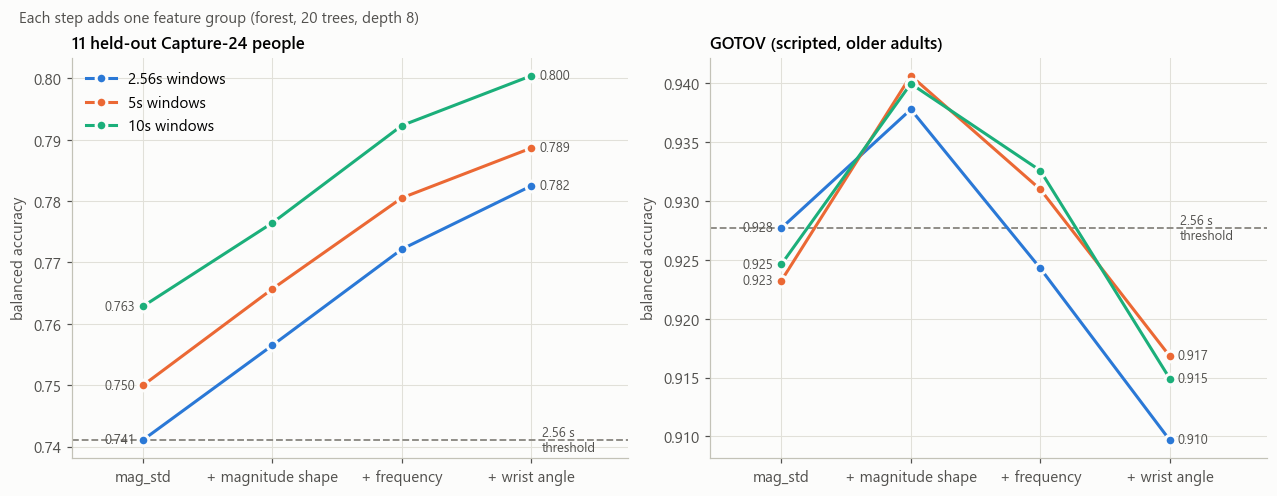

mag_std  + magnitude shape  + frequency  + wrist angle
held_out 2.56s    0.741              0.757        0.772          0.782
         5s       0.750              0.766        0.781          0.789
         10s      0.763              0.776        0.792          0.800
gotov    2.56s    0.928              0.938        0.924          0.910
         5s       0.923              0.941        0.931          0.917
         10s      0.925              0.940        0.933          0.915

In [8]:
ladder = [('1', 'mag_std'), ('1+2', '+ magnitude shape'), ('1+2+3', '+ frequency'), ('1+2+3+4', '+ wrist angle')]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=False, constrained_layout=True)
ablation = {}
for ax, (ds, title) in zip(axes, [('held_out', '11 held-out Capture-24 people'), ('gotov', 'GOTOV (scripted, older adults)')]):
    base = final['primary'][ds].loc['2.56s: threshold', 'balanced accuracy']
    ax.axhline(base, color=MUTED, linestyle='--', linewidth=1.2)
    ax.text(3.08, base, '2.56 s\nthreshold', color=INK_2, fontsize=8.5, va='center')
    for name in F.LENGTHS:
        ys = [final['primary'][ds].loc[f'{name}: {g}', 'balanced accuracy'] for g, _ in ladder]
        ablation[(ds, name)] = ys
        ax.plot(range(4), ys, marker='o', markersize=7, linewidth=2, color=COLOURS[name], markeredgecolor=SURFACE, markeredgewidth=2, label=f'{name} windows')
        ax.text(0 - 0.06, ys[0], f'{ys[0]:.3f}', ha='right', va='center', fontsize=8.5, color=INK_2)
        ax.text(3 + 0.06, ys[3], f'{ys[3]:.3f}', ha='left', va='center', fontsize=8.5, color=INK_2)
    ax.set_xticks(range(4), [l for _, l in ladder])
    ax.set_xlim(-0.55, 3.75)
    ax.set_title(title)
    ax.set_ylabel('balanced accuracy')
axes[0].legend(loc='upper left', frameon=False)
fig.suptitle('Each step adds one feature group (forest, 20 trees, depth 8)', x=0.01, ha='left', fontsize=10, color=INK_2)
plt.show()
display(pd.DataFrame({(ds, name): dict(zip([l for _, l in ladder], ys)) for (ds, name), ys in ablation.items()}).T)

**How to read this:** the dashed line is the 2.56 s threshold on the same panel's windows. On the held-out people every line climbs and the three window lengths stay in the same order (10 s highest). On GOTOV the lines peak at "+ magnitude shape" and then fall, and the 2.56 s, 5 s and 10 s lines are close together, because GOTOV is close to a ceiling. The table below the chart gives the exact values, because the line colours alone are not enough to tell the three lengths apart for every reader.

## 7. What the forest relies on

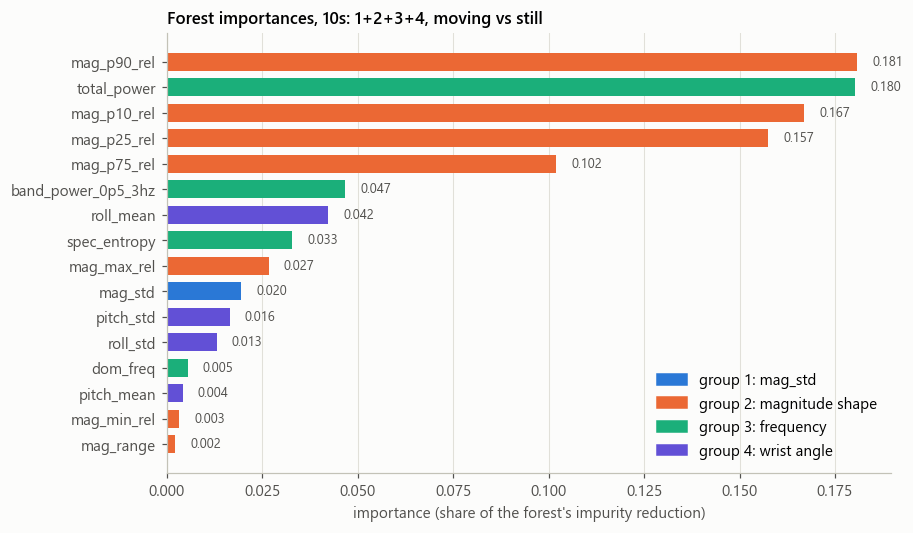

importance by group: {'1': 0.02, '2': 0.639, '3': 0.265, '4': 0.076}


In [9]:
cand = lock['primary']
imp = pd.Series(F.load_model_info('primary')['forests'][cand]['importances']).sort_values()
group_of = {f: g for g, fs in [('1', F.GROUP_1), ('2', F.GROUP_2), ('3', F.GROUP_3), ('4', F.GROUP_4)] for f in fs}
GROUP_COLOURS = {'1': '#2a78d6', '2': '#eb6834', '3': '#1baf7a', '4': '#6250d6'}
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.barh(imp.index, imp.values, color=[GROUP_COLOURS[group_of[f]] for f in imp.index], height=0.7)
for y_pos, v in enumerate(imp.values):
    ax.text(v + 0.004, y_pos, f'{v:.3f}', va='center', fontsize=8.5, color=INK_2)
ax.set_xlabel('importance (share of the forest\'s impurity reduction)')
ax.set_title(f'Forest importances, {cand}, moving vs still')
ax.grid(axis='y', visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLOURS.values()]
ax.legend(handles, ['group 1: mag_std', 'group 2: magnitude shape', 'group 3: frequency', 'group 4: wrist angle'], loc='lower right', frameon=False)
plt.show()
by_group = imp.groupby(imp.index.map(group_of)).sum().round(3)
print('importance by group:', by_group.to_dict())

**How to read this:** group 2 (magnitude shape) carries 64% of the forest's splits, frequency 27%, wrist angle 8% and `mag_std` itself only 2%. `mag_std` has such a low share because the percentiles are strongly related to it, and `total_power` (the biggest single bar) is almost the same quantity as `mag_std` squared. The forest gives the credit to whichever one it happens to split on first. So read the groups, not the single bars. Wrist angle is the smallest group, which matches it adding the least on Capture-24 (0.8 points at 10 s) and hurting on GOTOV.

## 8. False alerts at the 10 to 30 minute level

In [10]:
cand = lock['primary']
length = F.FEATURE_SETS[cand]['length']
short, long = F.load_predictions('primary', '2.56s'), F.load_predictions('primary', length)
long = long.assign(candidate=(long[f'forest::{cand}'] >= 0.5).astype(int))
rows = []
for ds, label in [('held_out', '11 held-out people'), ('gotov', 'GOTOV')]:
    a = F.block_scores(short[short['dataset'] == ds], ['threshold_pred'], F.SECONDS['2.56s']).assign(method='2.56 s threshold')
    b = F.block_scores(long[long['dataset'] == ds], ['candidate'], F.SECONDS[length]).assign(method=f'candidate ({cand})')
    rows.append(pd.concat([a, b]).assign(dataset=label))
blocks = pd.concat(rows).set_index(['dataset', 'method', 'block_min'])
display(blocks[['still blocks', 'active blocks', 'scored', 'AUC', 'false-alert rate', 'still-detection rate', 'new person: false-alert rate', 'new person: still detection']])

still blocks  active blocks  scored   AUC  false-alert rate  still-detection rate  new person: false-alert rate  new person: still detection
dataset            method                   block_min                                                                                                                                              
11 held-out people 2.56 s threshold         10                  382            352    True 0.904             0.205                 0.864                         0.207                        0.822
                                            30                  106            138    True 0.919             0.188                 0.877                         0.210                        0.783
                   candidate (10s: 1+2+3+4) 10                  382            351    True 0.946             0.148                 0.924                         0.157                        0.893
                                            30                  107            137    True 0.957             0.080                 0.897                         0.095                        0.888
GOTOV              2.56 s threshold         10                   55            126    True 0.995             0.016                 0.945                         0.040                        0.927
                                            30                    1             34   False   NaN               NaN                   NaN                           NaN                          NaN
                   candidate (10s: 1+2+3+4) 10                   56            132    True 0.993             0.015                 0.964                         0.015                        0.946
                                            30                    0             35   False   NaN               NaN                   NaN                           NaN                          NaN

**How to read this:** a block is flagged as inactive when the share of windows predicted moving falls at or below a threshold. These thresholds are chosen on the same blocks they're scored on, so the pooled rates are a best case. The "new person" columns pick the threshold from the other 10 people, which is closer to real use. On the held-out people the candidate lowers false alerts (30-minute pooled 18.8% to 8.0%, new-person 21.0% to 9.5%) and catches slightly more still blocks. The block counts at 30 minutes are small (about 100 still and 140 active blocks), so treat these as indicative. GOTOV has only 1 still block at 30 minutes and none for the candidate, so no rate is reported there. At 10 minutes GOTOV's false-alert rate is about 1.5% for both methods, so GOTOV can't tell them apart at this level.

## 9. Secondary target: very still (sleep) vs everything else

In [11]:
print('SLEEP vs EVERYTHING ELSE. 1 = not sleeping. GOTOV has no sleep: lying down awake for about 3 minutes stands in for it.')
both2 = pd.concat({'11 held-out people': final['secondary']['held_out'].drop(columns='windows'),
                   'GOTOV (lying vs rest)': final['secondary']['gotov'].drop(columns='windows')}, axis=1)
display(both2.loc[extra + order])
print('CV, balanced accuracy, top rows:')
display(cv_tables_secondary := summary['secondary'].pivot(index='feature_set', columns='model', values='balanced_accuracy').sort_values('forest', ascending=False).head(8))

SLEEP vs EVERYTHING ELSE. 1 = not sleeping. GOTOV has no sleep: lying down awake for about 3 minutes stands in for it.


11 held-out people       GOTOV (lying vs rest)      
                                 balanced accuracy   AUC     balanced accuracy   AUC
2.56s: threshold                             0.842 0.889                 0.637 0.895
5s: threshold                                0.853 0.900                 0.630 0.899
10s: threshold                               0.864 0.912                 0.632 0.904
2.56s: 1                                     0.842 0.889                 0.641 0.895
2.56s: 1+2                                   0.851 0.900                 0.597 0.897
2.56s: 1+2+3                                 0.851 0.904                 0.596 0.883
2.56s: 1+2+3+4                               0.875 0.931                 0.603 0.921
5s: 1                                        0.853 0.900                 0.632 0.898
5s: 1+2                                      0.864 0.916                 0.581 0.903
5s: 1+2+3                                    0.865 0.920                 0.584 0.889
5s: 1+2+3+4                                  0.886 0.942                 0.632 0.925
10s: 1                                       0.864 0.912                 0.637 0.903
10s: 1+2                                     0.874 0.930                 0.583 0.907
10s: 1+2+3                                   0.879 0.938                 0.584 0.900
10s: 1+2+3+4                                 0.895 0.953                 0.648 0.934
2.56s: 1+3                                   0.844 0.895                 0.640 0.880
2.56s: 1+4                                   0.874 0.930                 0.678 0.923
2.56s: 1+2 literal (diagnostic)              0.847 0.897                 0.592 0.896
everything (multi-scale)                     0.894 0.954                 0.618 0.931

CV, balanced accuracy, top rows:


model,forest,logistic,threshold
feature_set,,,
10s: 1+2+3+4,0.922,0.847,NaN
everything (multi-scale),0.922,0.850,NaN
5s: 1+2+3+4,0.913,0.833,NaN
10s: 1+2+3,0.911,0.843,NaN
10s: 1+2,0.906,0.839,NaN
2.56s: 1+2+3+4,0.902,0.822,NaN
2.56s: 1+4,0.902,0.805,NaN
5s: 1+2+3,0.897,0.828,NaN


**How to read this:** on Capture-24, the sleep target gives the clearest gain. The forest on 10 s windows reaches 0.922 in cross-validation against 0.871 for the 2.56 s threshold, and 0.895 against 0.841 on the held-out people. Here wrist angle is the group that helps most (10 s: 0.879 to 0.895), which makes sense, since lying down changes the wrist's tilt. GOTOV can't confirm it, though: it has no sleep, the stand-in is a few minutes of awake lying, and the forests flag only about a third of those windows. A GOTOV gain of 1.3 points with a CI of -4.0 to +6.9 says very little either way. The wider plan (time of day for sleep) is not tested here.

## 10. Things that looked off in the data

In [12]:
cand = lock['primary']
length = F.FEATURE_SETS[cand]['length']

# (a) GOTOV's ceiling and the standing question
g = F.load_predictions('primary', length)
g = g[g['dataset'] == 'gotov']
s_short = F.load_predictions('primary', '2.56s')
s_short = s_short[s_short['dataset'] == 'gotov']
print('GOTOV: median mag_std by activity (2.56 s)')
print(s_short.groupby('label')['mag_std'].median().sort_values().round(4).to_string())
no_stand = g[g['label'] != 'standing']
ns_short = s_short[s_short['label'] != 'standing']
print(f"\nGOTOV with standing removed: candidate {balanced_accuracy_score(no_stand['y'], no_stand[f'forest::{cand}'] >= 0.5):.3f}, "
      f"{length} threshold {balanced_accuracy_score(no_stand['y'], no_stand['threshold_pred']):.3f}, 2.56 s threshold {balanced_accuracy_score(ns_short['y'], ns_short['threshold_pred']):.3f}")

GOTOV: median mag_std by activity (2.56 s)
label
lyingDownRight    0.005
sittingSofa       0.006
lyingDownLeft     0.007
sittingCouch      0.007
sittingChair      0.008
standing          0.009
cycling           0.150
step              0.182
dishwashing       0.187
stakingShelves    0.204
walkingStairsUp   0.215
vacuumCleaning    0.226
walkingSlow       0.251
walkingNormal     0.310
walkingFast       0.324
syncJumping       0.926

GOTOV with standing removed: candidate 0.944, 10s threshold 0.954, 2.56 s threshold 0.958


In [13]:
# (b) does the wrist angle mean the same thing in the two datasets? Still windows only (sitting, sedentary)
ang_cols = ['pitch_mean', 'roll_mean', 'label', 'participant_id']
c24 = F.load_training('2.56s', columns=ang_cols)
c24 = c24[c24['label'] == 'sedentary']
ho = F.load_held_out('2.56s', columns=ang_cols)
ho = ho[ho['label'] == 'sedentary']
go = F.load_gotov('2.56s', columns=ang_cols)
go = go[go['label'].isin(F.GOTOV_SITTING)]
table = pd.DataFrame({
    'Capture-24 training, sedentary': c24[['pitch_mean', 'roll_mean']].describe().loc[['25%', '50%', '75%']].stack(),
    'Capture-24 held-out, sedentary': ho[['pitch_mean', 'roll_mean']].describe().loc[['25%', '50%', '75%']].stack(),
    'GOTOV, sitting': go[['pitch_mean', 'roll_mean']].describe().loc[['25%', '50%', '75%']].stack()})
display(table.unstack(0).round(1))

Capture-24 training, sedentary               Capture-24 held-out, sedentary               GOTOV, sitting               
                                      25%    50%    75%                            25%    50%    75%            25%    50%     75%
pitch_mean                        -17.900 27.000 51.500                        -26.500 27.500 51.800         28.100 44.300  65.200
roll_mean                         -37.300  3.900 59.000                        -24.000  8.800 62.500       -159.200  7.800 135.900

In [14]:
# (c) the held-out people versus the training people
meta = pd.read_csv(F.DATA_DIR / 'metadata.csv', index_col='pid')
print('age groups, training people:', meta.loc[train_ids, 'age'].value_counts().to_dict())
print('age groups, held-out people:', meta.loc[test_ids, 'age'].value_counts().to_dict())

# (d) per-person spread of the gain, 11 held-out people
long = F.load_predictions('primary', length)
long = long[long['dataset'] == 'held_out']
short = F.load_predictions('primary', '2.56s')
mask = F.inside_longer(short, F.load_predictions('primary', length), F.SECONDS[length])
short_h = short[(short['dataset'] == 'held_out').to_numpy() & mask]
per = pd.DataFrame({
    'threshold (matched)': short_h.groupby('participant_id').apply(lambda d: balanced_accuracy_score(d['y'], d['threshold_pred']), include_groups=False),
    'candidate': long.groupby('participant_id').apply(lambda d: balanced_accuracy_score(d['y'], d[f'forest::{cand}'] >= 0.5), include_groups=False)})
per['gain (points)'] = 100 * (per['candidate'] - per['threshold (matched)'])
per['age'] = meta.loc[per.index, 'age']
display(per.round(3))
print('people with a positive gain:', int((per['gain (points)'] > 0).sum()), 'of', len(per))

age groups, training people: {'18-29': 42, '30-37': 37, '38-52': 36, '53+': 25}
age groups, held-out people: {'53+': 9, '18-29': 1, '38-52': 1}


,threshold (matched),candidate,gain (points),age
participant_id,,,,
P012,0.823,0.852,2.959,53+
P057,0.732,0.798,6.589,53+
P064,0.693,0.725,3.195,53+
P076,0.815,0.871,5.619,53+
P081,0.640,0.670,2.972,53+
P092,0.735,0.819,8.386,53+
P096,0.692,0.801,10.959,18-29
P107,0.856,0.898,4.160,38-52
P111,0.803,0.870,6.772,53+


people with a positive gain: 11 of 11


**How to read these:**

- **GOTOV standing:** its median `mag_std` (0.009 g) sits with the sitting classes (0.006 to 0.008 g), but the Walmsley rule makes it "moving", so correct "still" calls on standing count as errors. Take standing out and every method rises to 0.94 to 0.96, and the threshold edges ahead of the candidate.
- **Wrist angle:** GOTOV sitting has a median roll of 8 degrees but a middle half spanning -159 to +136, against -37 to +59 for Capture-24. The two devices are probably mounted with different axes, so angle-based features don't transfer, which fits them hurting on GOTOV. Realigning the axes is outside this test.
- **Held-out people:** 9 of 11 are aged 53+, against 25 of 140 in training. Every one of the 11 gains (about 3 to 11 points), so the result isn't carried by one person.

## Appendix: what is cached and how to re-run

| Step | Function | Cache |
|---|---|---|
| Windows, all 151 people | `feature_sets.build_capture24_person` | `data/processed/capture24_windows/feature_sets/` |
| Windows, GOTOV | `feature_sets.build_gotov` | `data/processed/eda/gotov_feature_sets_*.parquet` |
| Cross-validation | `feature_sets.run_cv(target)` | `data/processed/feature_combinations/cv_*.parquet` |
| Locking the candidate | `feature_sets.lock_candidates()` | `locked_candidates.json` |
| Final fits and predictions | `feature_sets.run_final(target)` | `final_*/predictions_*.parquet` |

To start again from scratch, delete `data/processed/feature_combinations/`. That also resets the lock, so the choice of candidate is made again, and only before the held-out people are scored.